#lab 1
Program 1: Build and Train a Neural Network on MNIST with Custom Activation and Loss Functions 🔧 Concepts Covered: Declaring tensors

In [ ]:
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

# Load and preprocess data
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train = x_train.reshape(-1, 784) / 255.0
x_test = x_test.reshape(-1, 784) / 255.0
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# Custom activation function
def custom_relu(x):
    return tf.maximum(0.1 * x, x)

# Custom loss function
def custom_cross_entropy(y_true, y_pred):
    return -tf.reduce_mean(tf.reduce_sum(y_true * tf.math.log(y_pred + 1e-10), axis=1))

# Model definition using functional API
inputs = tf.keras.Input(shape=(784,))
x = tf.keras.layers.Dense(128)(inputs)
x = tf.keras.layers.Activation(custom_relu)(x)
x = tf.keras.layers.Dense(64, activation='relu')(x)
outputs = tf.keras.layers.Dense(10, activation='softmax')(x)

model = tf.keras.Model(inputs=inputs, outputs=outputs)

# Compile model
model.compile(optimizer='adam',
              loss=custom_cross_entropy,
              metrics=['accuracy'])

# Train the model
model.fit(x_train, y_train, batch_size=64, epochs=5, verbose=1)

# Evaluate
test_loss, test_acc = model.evaluate(x_test, y_test)
print("Test Accuracy:", test_acc)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8629 - loss: 0.4843
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9626 - loss: 0.1238
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9748 - loss: 0.0840
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9808 - loss: 0.0638
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9855 - loss: 0.0452
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9694 - loss: 0.1029
Test Accuracy: 0.9749000072479248


# **lab 2**
Program 2: TensorFlow Computational Graph with Nested Operations and Unit Tests

In [ ]:
import tensorflow as tf
import unittest

# function with nested operations
def compute_nested_graph(x, y):
    a= tf.multiply(x, y)
    b= tf.add(a, x)
    c= tf.square(b)
    return c


#Unit test using tf.test.Testcase
class TestTensorflowGraph(tf.test.TestCase):
    def test_nested_operations(self):
        x = tf.constant(3.0)
        y = tf.constant(2.0)
        result = compute_nested_graph(x, y)
        self.assertEqual(self.evaluate(result), (3*2+3)**2)


#Run test
unittest.main(argv=[''], verbosity=2, exit=False)

test_nested_operations (__main__.TestTensorflowGraph.test_nested_operations)
TestTensorflowGraph.test_nested_operations ... ok
test_session (__main__.TestTensorflowGraph.test_session)
TestTensorflowGraph.test_session
Use cached_session instead. (deprecated) ... skipped 'Not a test.'

----------------------------------------------------------------------
Ran 2 tests in 0.016s

OK (skipped=1)


# **lab 3**

Program 3: Multi-Layer Model with Manual Loss and Multiple Executors

In [ ]:
import tensorflow as tf
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Create dataset
X, y = make_classification(n_samples=1000, n_features=20, n_classes=2)
# Convert to numpy arrays before splitting
X_np = X.astype('float32')
y_np = y.reshape(-1, 1).astype('float32')


# Split
x_train_np, x_test_np, y_train_np, y_test_np = train_test_split(X_np, y_np, test_size=0.2)

# Convert back to TensorFlow tensors after splitting
x_train = tf.convert_to_tensor(x_train_np, dtype=tf.float32)
x_test = tf.convert_to_tensor(x_test_np, dtype=tf.float32)
y_train = tf.convert_to_tensor(y_train_np, dtype=tf.float32)
y_test = tf.convert_to_tensor(y_test_np, dtype=tf.float32)


# Define model
class MLP(tf.keras.Model):
    def __init__(self):
        super().__init__()
        self.d1 = tf.keras.layers.Dense(64, activation='relu')
        self.d2 = tf.keras.layers.Dense(32, activation='relu')
        self.out = tf.keras.layers.Dense(1, activation='sigmoid')

    def call(self, x):
        x = self.d1(x)
        x = self.d2(x)
        return self.out(x)

# Instantiate model
model = MLP()
loss_fn = tf.keras.losses.BinaryCrossentropy()
optimizer = tf.keras.optimizers.Adam()

# Training loop (batch + manual)
batch_size = 32
for epoch in range(5):
    for i in range(0, len(x_train), batch_size):
        x_batch = x_train[i:i+batch_size]
        y_batch = y_train[i:i+batch_size]
        with tf.GradientTape() as tape:
            logits = model(x_batch)
            loss = loss_fn(y_batch, logits)
        grads = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(grads, model.trainable_variables))
    print(f"Epoch {epoch+1} Loss: {loss.numpy():.4f}")

# Evaluate
preds = tf.round(model(x_test))
accuracy = tf.reduce_mean(tf.cast(tf.equal(preds, y_test), tf.float32))
print("Test Accuracy:", accuracy.numpy())

Epoch 1 Loss: 0.4881
Epoch 2 Loss: 0.3124
Epoch 3 Loss: 0.2075
Epoch 4 Loss: 0.1602
Epoch 5 Loss: 0.1413
Test Accuracy: 0.92


# lab 4
Implementing Bagging and Random Forest with Variable Importance

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



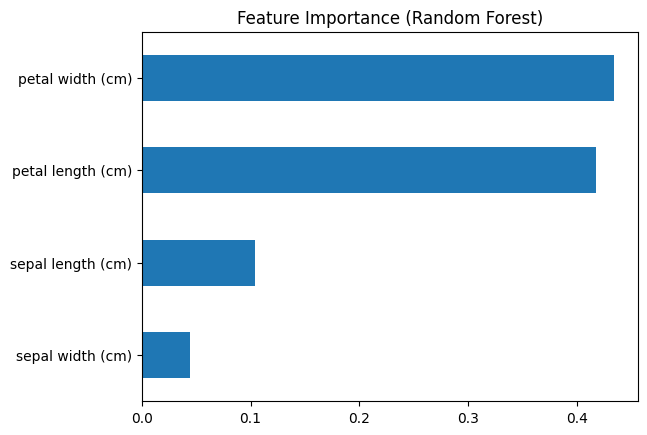

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
import pandas as pd
import matplotlib.pyplot as plt

# Load data
iris = load_iris()
X = iris.data
y = iris.target

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Train Random Forest (Bagging ensemble using bootstrap sampling)
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Report
print("Classification Report:\n", classification_report(y_test, y_pred))

# Feature Importance
feature_importance = pd.Series(model.feature_importances_, index=iris.feature_names)
feature_importance.sort_values().plot(kind='barh', title='Feature Importance (Random Forest)')
plt.show()


#lab5
# Implementing AdaBoost for Weak Learner Enhancement

In [ ]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

# Create binary classification dataset
X, y = make_classification(n_samples=500, n_features=10, n_informative=5, n_redundant=0, random_state=1)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Weak learner: shallow decision tree
base_learner = DecisionTreeClassifier(max_depth=1)

# AdaBoost ensemble

ada_model = AdaBoostClassifier(estimator=base_learner, n_estimators=100, learning_rate=1.0, random_state=42)

ada_model.fit(X_train, y_train)

# Predict
y_pred = ada_model.predict(X_test)

# Results
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))


Accuracy: 0.78
Confusion Matrix:
 [[68 11]
 [22 49]]


# lab 6
#  Compare AdaBoost vs CatBoost (with fallback to GradientBoosting if CatBoost not installed)

In [ ]:
# Install CatBoost in Colab (if not already available)
!pip install -q catboost

# Import libraries
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import warnings

# Create dataset
X, y = make_classification(
    n_samples=500,
    n_features=10,
    n_informative=5,
    n_redundant=0,
    random_state=2
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Weak learner for AdaBoost
base_learner = DecisionTreeClassifier(max_depth=1, random_state=42)

# AdaBoost (handle sklearn version compatibility)
try:
    ada = AdaBoostClassifier(
        estimator=base_learner,
        n_estimators=100,
        learning_rate=1.0,
        random_state=42
    )
except TypeError:
    ada = AdaBoostClassifier(
        base_estimator=base_learner,
        n_estimators=100,
        learning_rate=1.0,
        random_state=42
    )

ada.fit(X_train, y_train)
ada_acc = accuracy_score(y_test, ada.predict(X_test))

# Try CatBoost; fallback to GradientBoosting if not available
try:
    from catboost import CatBoostClassifier
    cat = CatBoostClassifier(
        iterations=100,
        learning_rate=0.1,
        depth=6,
        verbose=0,
        random_state=42
    )
    cat.fit(X_train, y_train)
    cat_acc = accuracy_score(y_test, cat.predict(X_test))

    print("✅ AdaBoost accuracy:        ", ada_acc)
    print("✅ CatBoost accuracy:        ", cat_acc)

except Exception as e:
    warnings.warn("CatBoost not available. Using GradientBoostingClassifier as fallback.\n" + str(e))
    gb = GradientBoostingClassifier(random_state=42)
    gb.fit(X_train, y_train)
    gb_acc = accuracy_score(y_test, gb.predict(X_test))

    print("✅ AdaBoost accuracy:        ", ada_acc)
    print("✅ GradientBoosting accuracy:", gb_acc)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 6.3 MB/s eta 0:00:00
✅ AdaBoost accuracy:         0.94
✅ CatBoost accuracy:         0.92


# lab 7
Q-Learning for Gridworld (Value-Based RL) 🧠 Concept Q-Learning is a model-free reinforcement learning algorithm that learns the value of actions in states using a Q-table. Explanation The table shows action-value estimates for each state.

Final state (goal) has no future reward, so Q-values are 0.

Agent learns to move right to reach the goal.

In [ ]:
import numpy as np

states = 5
actions = [0,1]
q_table = np.zeros((states, len(actions)))

alpha = 0.1
gamma = 0.9
epsilon = 0.1
episodes = 100

rewards = [0,0,0,0,1]

for ep in range(episodes):
    state = 0
    while state != 4:
      if np.random.rand() < epsilon:
          action = np.random.choice(actions)
      else:
          action = np.argmax(q_table[state])
      next_state = state + 1 if action == 1 else state - 1
      next_state = max(0, min(states - 1, next_state))
      reward = rewards[next_state]
      q_table[state][action] += alpha * (reward + gamma * np.max(q_table[next_state]) - q_table[state][action])
      state = next_state

print("Q-Table:\n", q_table)

# lab 8
Hyperparameter Tuning Using GridSearchCV with SVM
Objective: Perform grid search to tune the C and gamma parameters for an SVM on the Iris dataset. Explanation: Uses GridSearchCV with 5-fold cross-validation.

Automatically tries all C and gamma combinations.

The pipeline ensures scaling is done before model training.

In [ ]:
# Import required libraries
import numpy as np
import pandas as pd
from sklearn import datasets
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load dataset (Iris dataset for example)
iris = datasets.load_iris()
X = iris.data
y = iris.target

# Split the data (70% training, 30% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Define the SVM model
svm = SVC()

# Define the hyperparameter grid
param_grid = {
    'C': [0.1, 1, 10, 100],              # Regularization parameter
    'kernel': ['linear', 'poly', 'rbf', 'sigmoid'],  # Kernel type
    'gamma': ['scale', 'auto']           # Kernel coefficient
}

# Apply Grid Search with 5-fold cross-validation
grid_search = GridSearchCV(estimator=svm, param_grid=param_grid,
                           cv=5, n_jobs=-1, verbose=2)

# Fit the model
grid_search.fit(X_train, y_train)

# Print the best parameters and best cross-validation score
print("Best Parameters found:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:", grid_search.best_score_)

# Test set predictions
y_pred = grid_search.predict(X_test)

# Evaluation metrics
print("\nTest Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test,y_pred))


Fitting 5 folds for each of 32 candidates, totalling 160 fits
Best Parameters found: {'C': 1, 'gamma': 'scale', 'kernel': 'poly'}
Best Cross-Validation Accuracy: 0.9714285714285715

Test Accuracy: 0.9777777777777777

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      0.92      0.96        13
           2       0.93      1.00      0.96        13

    accuracy                           0.98        45
   macro avg       0.98      0.97      0.97        45
weighted avg       0.98      0.98      0.98        45


Confusion Matrix:
 [[19  0  0]
 [ 0 12  1]
 [ 0  0 13]]


# lab 9
# Random Forest : Evaluating a Classification Model in Python


Model Performance Metrics
Accuracy       : 1.0000
Precision      : 1.0000
Recall         : 1.0000
F1 Score       : 1.0000
ROC-AUC Score  : 1.0000

Confusion Matrix:
[[17  0]
 [ 0 13]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        17
           1       1.00      1.00      1.00        13

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



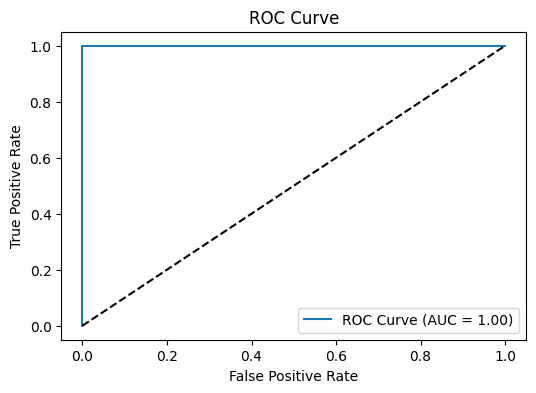

In [ ]:
# Import Libraries
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)
import matplotlib.pyplot as plt

# Load Iris Dataset
data = load_iris()
X, y = data.data, data.target

# For binary classification - use only class 0 and 1
X = X[y != 2]
y = y[y != 2]

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Train Random Forest model
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# Predict on test data
y_pred = model.predict(X_test)
y_pred_prob = model.predict_proba(X_test)[:, 1]  # For ROC-AUC

# Performance Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
report = classification_report(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_prob)

# Print all metrics
print("Model Performance Metrics")
print(f"Accuracy       : {accuracy:.4f}")
print(f"Precision      : {precision:.4f}")
print(f"Recall         : {recall:.4f}")
print(f"F1 Score       : {f1:.4f}")
print(f"ROC-AUC Score  : {roc_auc:.4f}")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(report)

# Plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')  # Diagonal line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# lab 10
# Linear Regression : Evaluating a Regression Model in Python


In [ ]:

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Load dataset
data = load_diabetes()

X = data.data
y = data.target

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Evaluate
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display results
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R² Score:",r2)

Mean Absolute Error (MAE): 42.79409467959994
Mean Squared Error (MSE): 2900.193628493482
Root Mean Squared Error (RMSE): 53.85344583676593
R² Score: 0.4526027629719195
